### Many ways to create DT we are using CART (Classification and Regression Tree)

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier , plot_tree
from sklearn.metrics import accuracy_score
from sklearn.compose import ColumnTransformer , make_column_selector,make_column_transformer 
from sklearn.preprocessing import OneHotEncoder 
from sklearn.pipeline import Pipeline
from tqdm import tqdm

from sklearn.model_selection import train_test_split

import os 
os.chdir('E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets\Cases\Wisconsin')

In [9]:
wisc = pd.read_csv("BreastCancer.csv")
wisc

,Code,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
0,61634,5,4,3,1,2,2,2,3,1,Benign
1,63375,9,1,2,6,4,10,7,7,2,Malignant
2,76389,10,4,7,2,2,8,6,1,1,Malignant
3,95719,6,10,10,10,8,10,7,10,7,Malignant
4,128059,1,1,1,1,2,5,5,1,1,Benign
...,...,...,...,...,...,...,...,...,...,...,...
694,1369821,10,10,10,10,5,10,10,10,7,Malignant
695,1371026,5,10,10,10,4,10,5,6,3,Malignant
696,1371920,5,1,1,1,2,1,3,2,1,Benign
697,8233704,4,1,1,1,1,1,2,1,1,Benign


In [19]:
wisc['Class'].unique()

<ArrowStringArray>
['Benign', 'Malignant']
Length: 2, dtype: str

In [12]:

X , y = wisc.drop('Class', axis=1), wisc['Class']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26 ,stratify=y)

In [32]:
y_train[y_train == 'Benign'].count()

np.int64(320)

In [33]:
y_train[y_train == 'Malignant'].count()    
for counting gini index 


# Total Samples ($N$): Add up all samples in the node.
# Class Probabilities ($p_i$): Divide each class count by the total samples.
# Square Probabilities: Square each resulting probability value.$$(p_{\text{Benign}})^2, \quad (p_{\text{Malignant}})^2$$
# Sum & Subtract: Add the squares together, then subtract the sum from $1$.

np.int64(169)

# Decision Tree Classifier For Breast Cancer

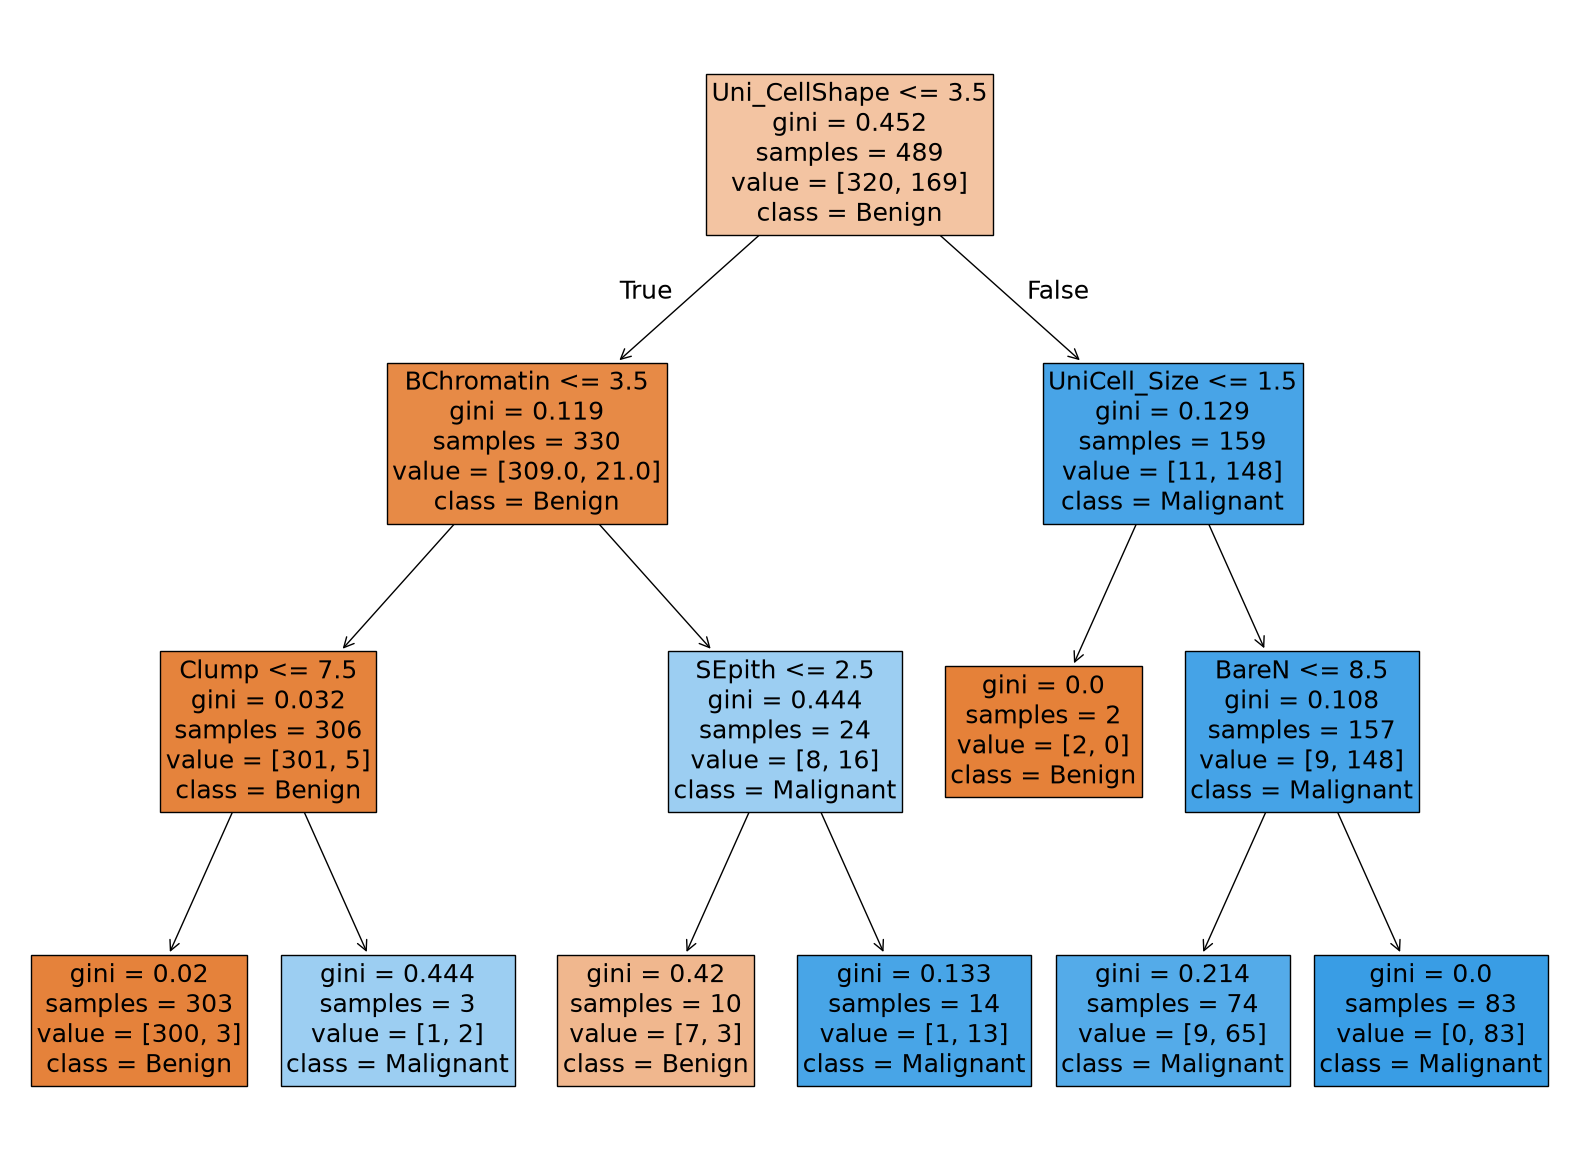

In [23]:
wisc = pd.read_csv("BreastCancer.csv")
X , y = wisc.drop('Class', axis=1), wisc['Class']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26 ,stratify=y)


dtc = DecisionTreeClassifier(random_state=10, max_depth=3)
dtc.fit(X_train, y_train)
plt.figure(figsize=(20,15))
plot_tree(dtc , feature_names=list(X.columns),
         class_names=['Benign','Malignant'] , filled=True, fontsize = 18  )
plt.show()

# Benign -> अघातक
# Malignant -> घातक

# min_samples_split

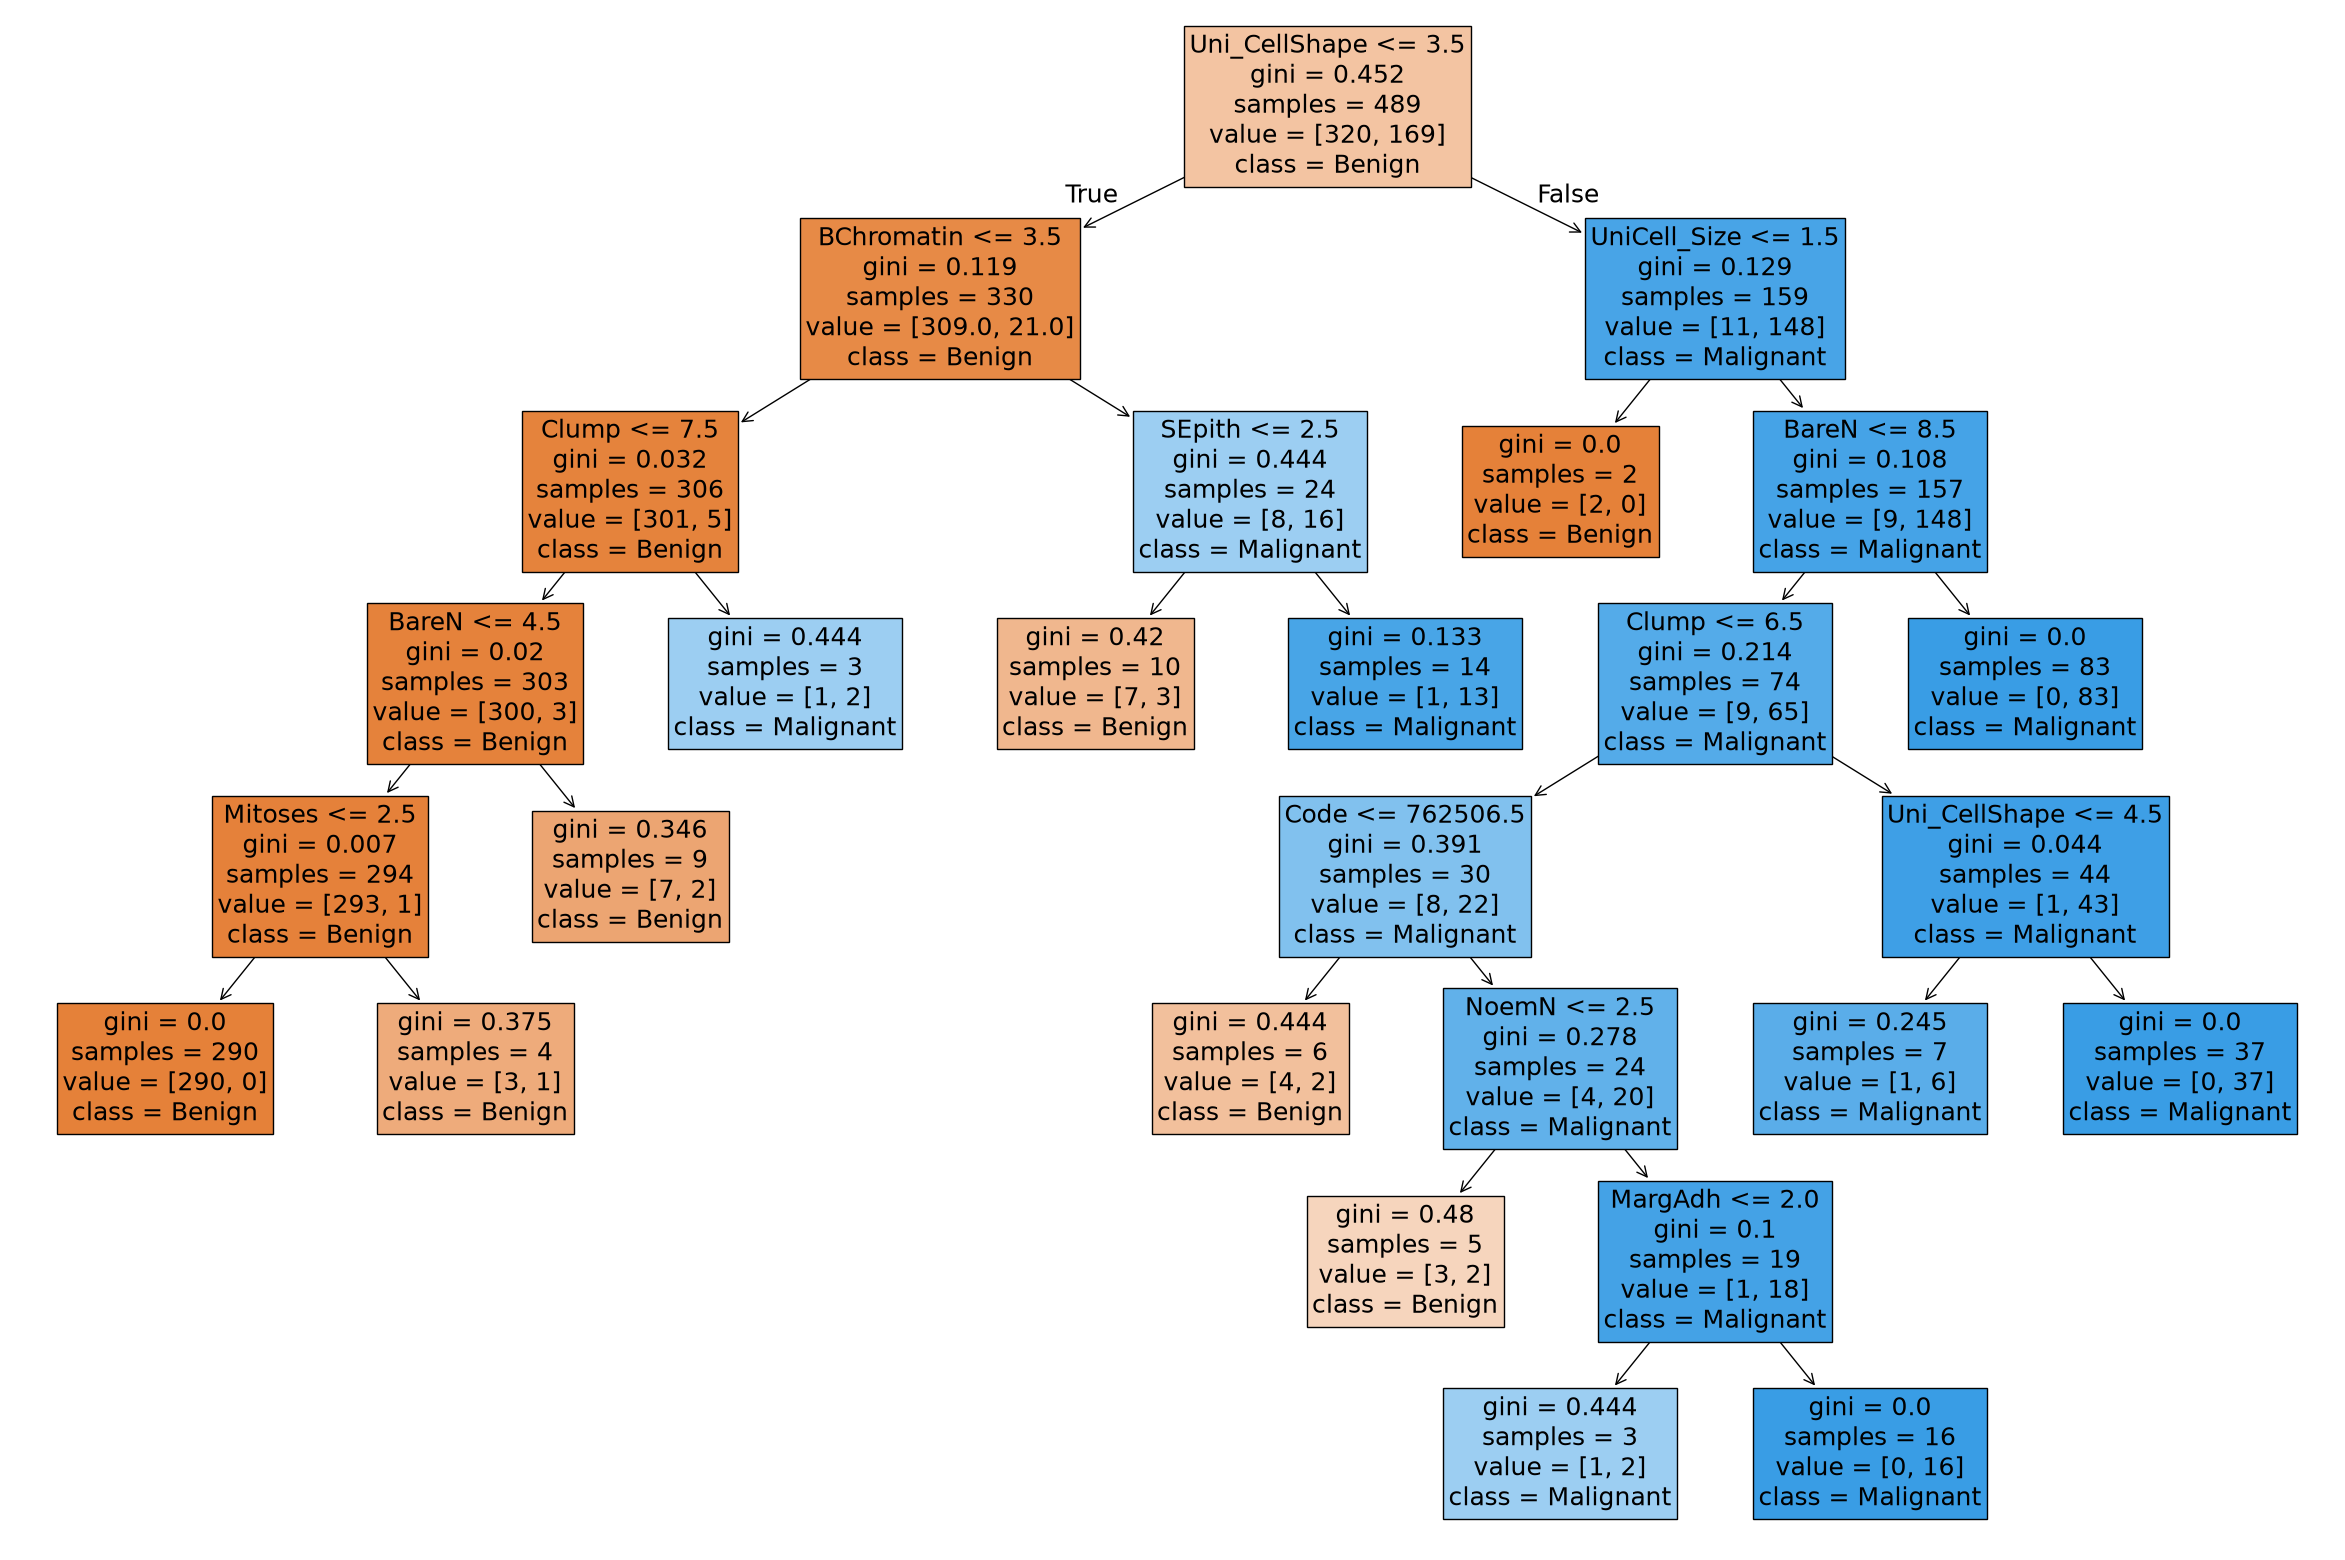

In [44]:
wisc = pd.read_csv("BreastCancer.csv")
X , y = wisc.drop('Class', axis=1), wisc['Class']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26 ,stratify=y)


dtc = DecisionTreeClassifier(random_state=26,min_samples_split=18)
dtc.fit(X_train, y_train)
plt.figure(figsize=(30,20))
plot_tree(dtc , feature_names=list(X.columns),
         class_names=['Benign','Malignant'] , filled=True, fontsize = 18
         )
plt.show()

# max_depth  
# min_samples_split   
# min_samples_leaf

In [48]:
wisc = pd.read_csv("BreastCancer.csv")
X , y = wisc.drop('Class', axis=1), wisc['Class']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26 ,stratify=y)

depths = [None ,2,3,4,5,6,7]
min_split = [2,5,10,20,50]
min_leaf = [1,5,10,20,50]
scores = []

for d in depths:
    for s in min_split:
        for f in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26 , max_depth=d , min_samples_split=s, min_samples_leaf=f)
            dtc.fit(X_train , y_train)
            y_pred = dtc.predict(X_test)
            scores.append([d,s,f,accuracy_score(y_test, y_pred)])

df_scores  = pd.DataFrame(scores , columns=['Depth','Splits','Leaf','Score'])
df_scores.sort_values('Score' , ascending=False)

,Depth,Splits,Leaf,Score
1,NaN,2,5,0.952381
6,NaN,5,5,0.952381
11,NaN,10,5,0.952381
151,7.0,2,5,0.952381
100,5.0,2,1,0.952381
...,...,...,...,...
149,6.0,50,50,0.895238
164,7.0,10,50,0.895238
159,7.0,5,50,0.895238
169,7.0,20,50,0.895238


# Decision Tree For Student Dataset

In [53]:

os.chdir('E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets\Cases\student_performance')
stud = pd.read_csv("student_dataset_10000_rows.csv")
stud

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed
...,...,...,...,...,...,...,...,...
9995,2,58,9,7,8,88,69.31,Not Placed
9996,7,98,6,9,4,87,100.00,Placed
9997,10,44,8,5,10,37,95.94,Placed
9998,10,75,7,5,8,52,88.61,Placed


In [52]:
X , y = stud.drop('placement_status', axis=1), stud['placement_status']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26 ,stratify=y)

depths = [None ,2,3,4,5,6,7]
min_split = [2,0.05,0.01,0.1,0.2,0.3]
min_leaf = [1,0.05,0.01,0.1,0.2,0.3]
scores = []

for d in depths:
    for s in min_split:
        for f in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26 , max_depth=d , min_samples_split=s, min_samples_leaf=f)
            dtc.fit(X_train , y_train)
            y_pred = dtc.predict(X_test)
            scores.append([d,s,f,accuracy_score(y_test, y_pred)])

df_scores  = pd.DataFrame(scores , columns=['Depth','Splits','Leaf','Score'])
df_scores.sort_values('Score' , ascending=False)

,Depth,Splits,Leaf,Score
0,NaN,2.00,1.00,1.000000
1,NaN,2.00,0.05,1.000000
2,NaN,2.00,0.01,1.000000
3,NaN,2.00,0.10,1.000000
7,NaN,0.05,0.05,1.000000
...,...,...,...,...
227,7.0,0.05,0.30,0.856667
233,7.0,0.01,0.30,0.856667
239,7.0,0.10,0.30,0.856667
245,7.0,0.20,0.30,0.856667


# Decision Tree on Hr dataset    
(find Best DT on hr dataset -> OHE -> DT -> features and features_importance_)

In [100]:

os.chdir('E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets\Cases\human-resources-analytics')
stud = pd.read_csv("HR_comma_sep.csv")
stud

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.10,0.77,6,247,4,0,1,0,sales,low
3,0.92,0.85,5,259,5,0,1,0,sales,low
4,0.89,1.00,5,224,5,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14990,0.40,0.57,2,151,3,0,1,0,support,low
14991,0.37,0.48,2,160,3,0,1,0,support,low
14992,0.37,0.53,2,143,3,0,1,0,support,low
14993,0.11,0.96,6,280,4,0,1,0,support,low


In [101]:
ohe = OneHotEncoder(sparse_output=False , drop='first').set_output(transform='pandas')
cols_trs = make_column_transformer(
    ( ohe, make_column_selector(dtype_include='object')),
    ( 'passthrough', make_column_selector(dtype_include=['int64', 'float64'])),
    verbose_feature_names_out=False
).set_output(transform = 'pandas')


In [102]:
X , y = stud.drop('left', axis=1), stud['left']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26 ,stratify=y)



depths = [None ,2,3,4,5,6,7]
min_split = [2,0.05,0.01,0.1,0.2,0.3]
min_leaf = [1,0.05,0.01,0.1,0.2,0.3]
scores = []

for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26 , max_depth=d , min_samples_split=s, min_samples_leaf=f)

            pip = Pipeline([('ohe' , cols_trs),('TREE',dtc)])

            pip.fit(X_train, y_train)
            y_pred = pip.predict(X_test) 
              
            scores.append([d,s,f,accuracy_score(y_test, y_pred)])

df_scores  = pd.DataFrame(scores , columns=['Depth','Splits','Leaf','Score'])
df_scores.sort_values('Score' , ascending=False)

100%|██████████| 7/7 [00:12<00:00,  1.77s/it]


,Depth,Splits,Leaf,Score
216,7.0,2.00,1.0,0.978662
228,7.0,0.01,1.0,0.977551
6,NaN,0.05,1.0,0.977328
222,7.0,0.05,1.0,0.977328
12,NaN,0.01,1.0,0.976884
...,...,...,...,...
227,7.0,0.05,0.3,0.803734
233,7.0,0.01,0.3,0.803734
239,7.0,0.10,0.3,0.803734
245,7.0,0.20,0.3,0.803734


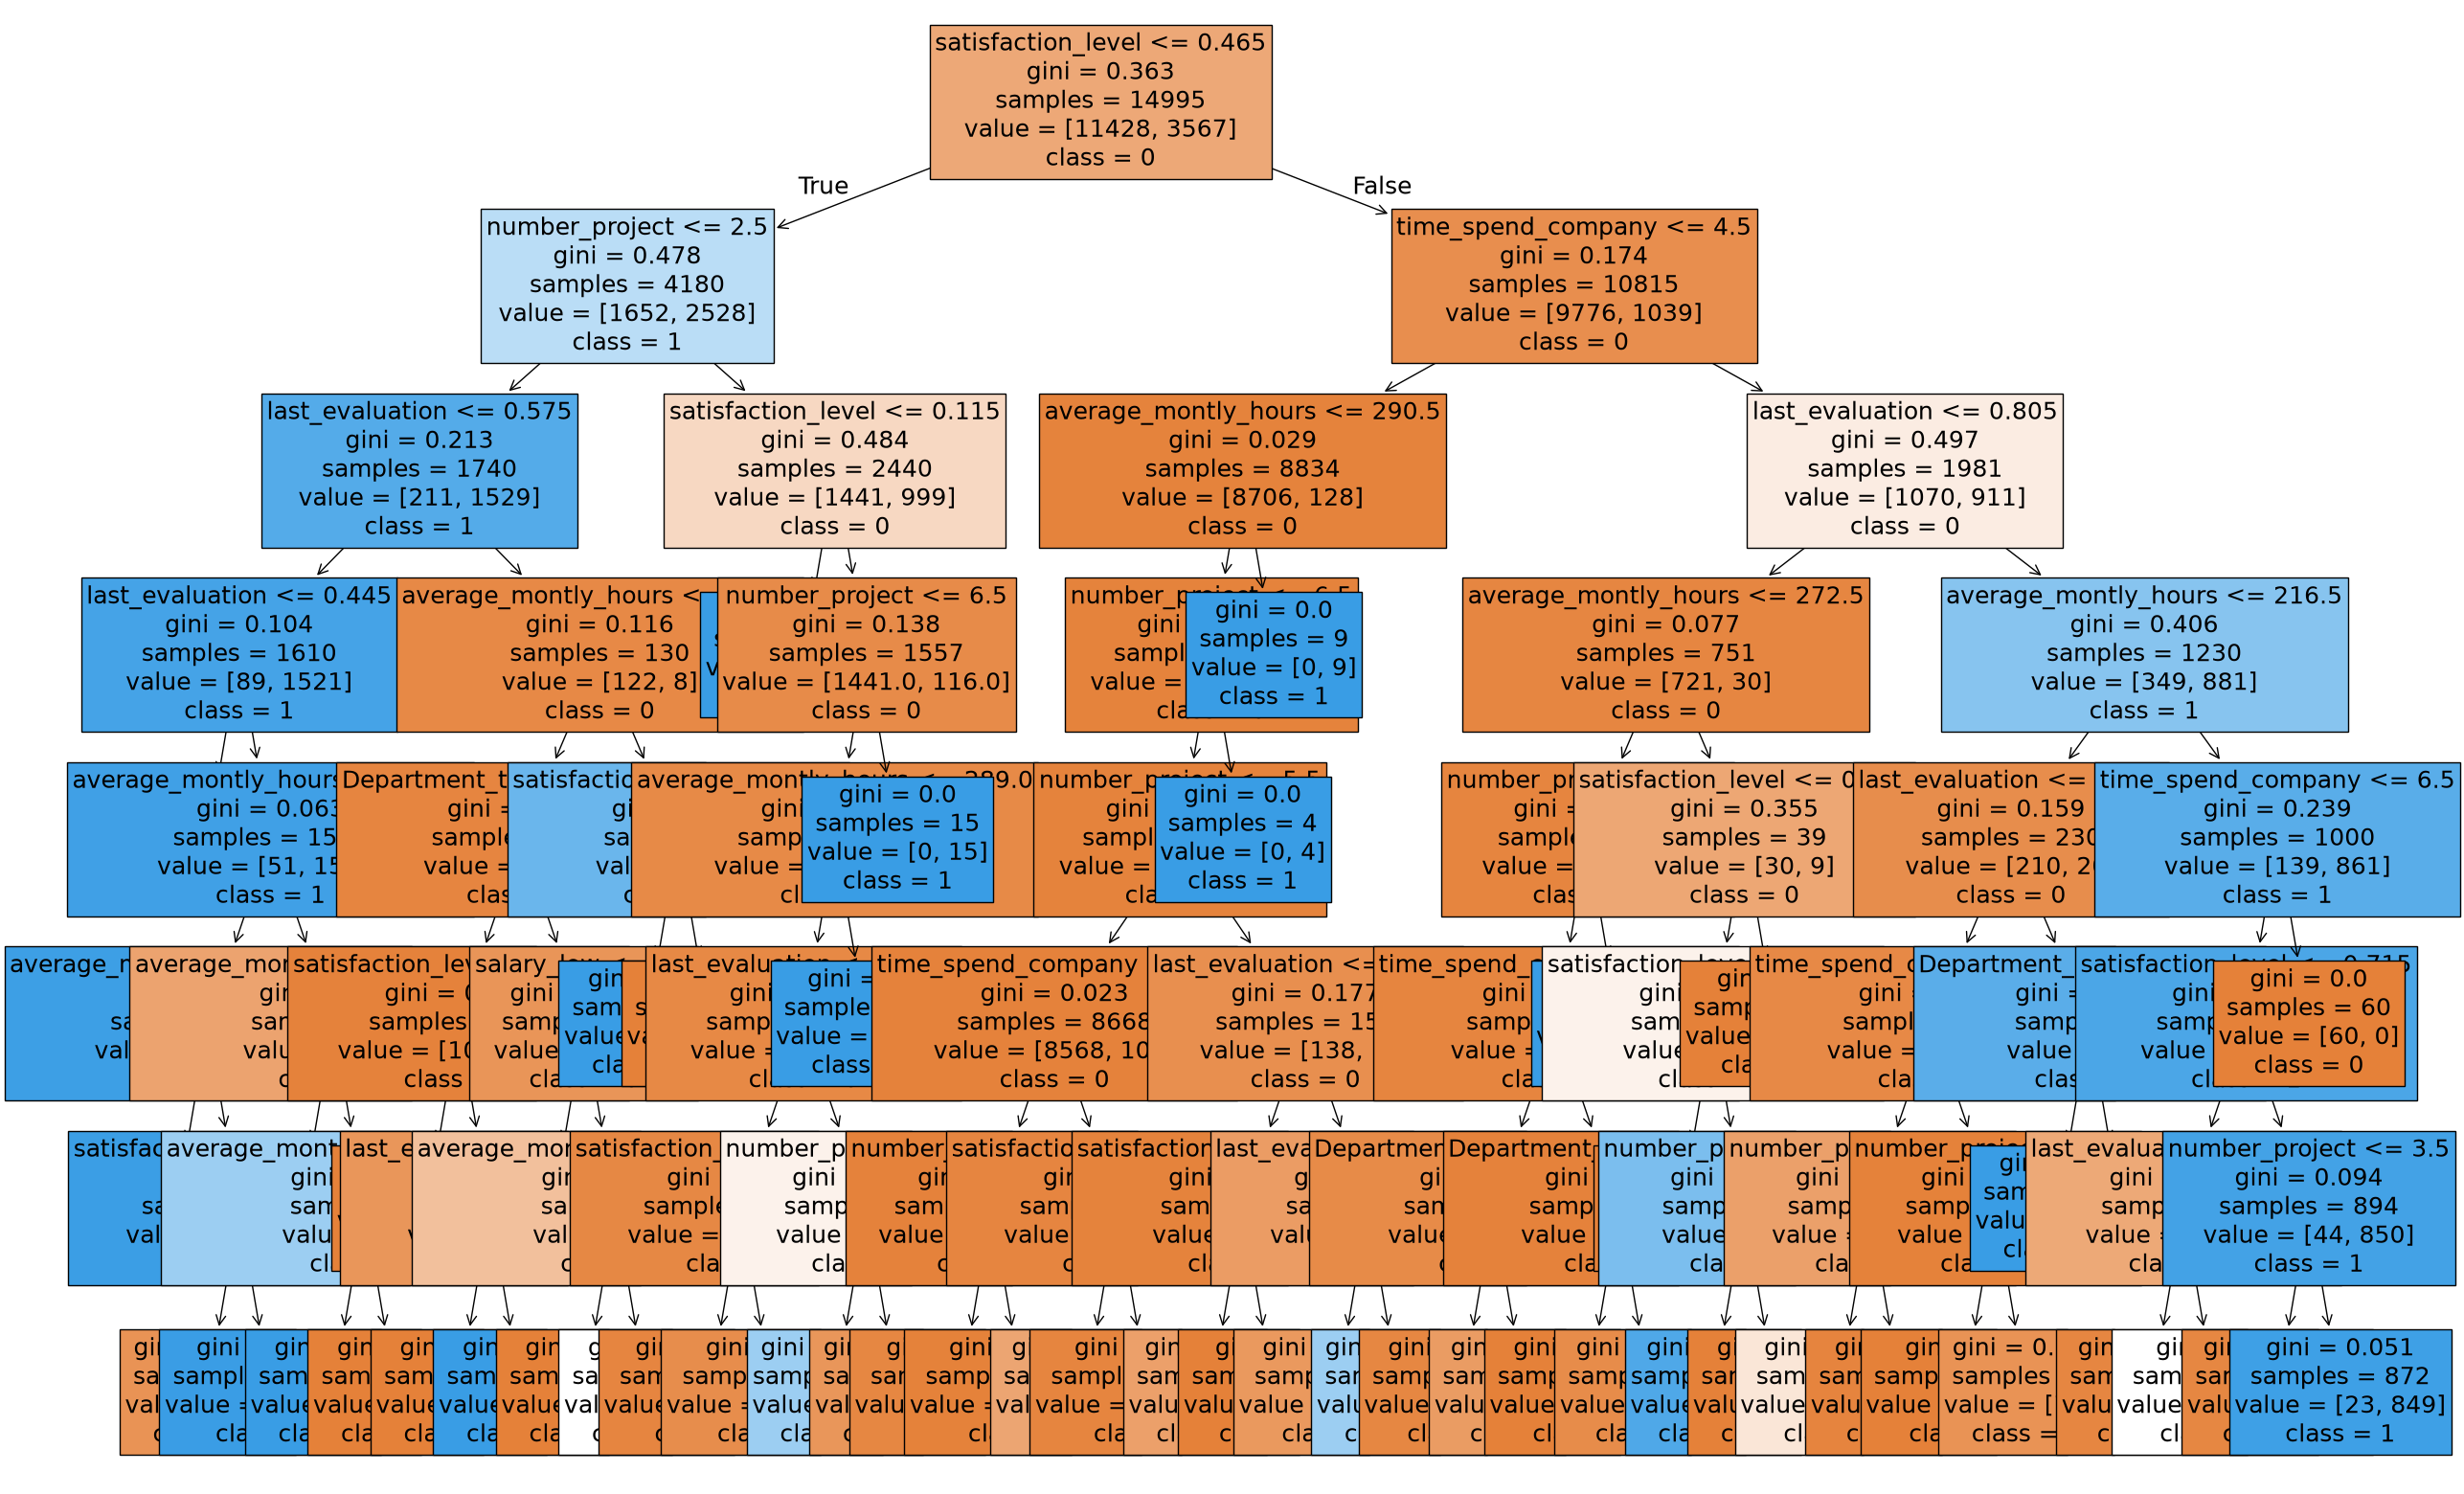

In [103]:
# best tree
stud = pd.read_csv("HR_comma_sep.csv")
X , y = stud.drop('left', axis=1), stud['left']  


bestTree = DecisionTreeClassifier(random_state=26,min_samples_split=2, min_samples_leaf=1,max_depth=7)
X_ohe = cols_trs.fit_transform(X)
bestTree.fit(X_ohe , y)
 
plt.figure(figsize=(30,20))
plot_tree(bestTree , feature_names=list(X_ohe.columns),
         class_names=['0','1'] , filled=True, fontsize = 18
         )
plt.show()

Text(0, 0.5, 'Features importances plot')

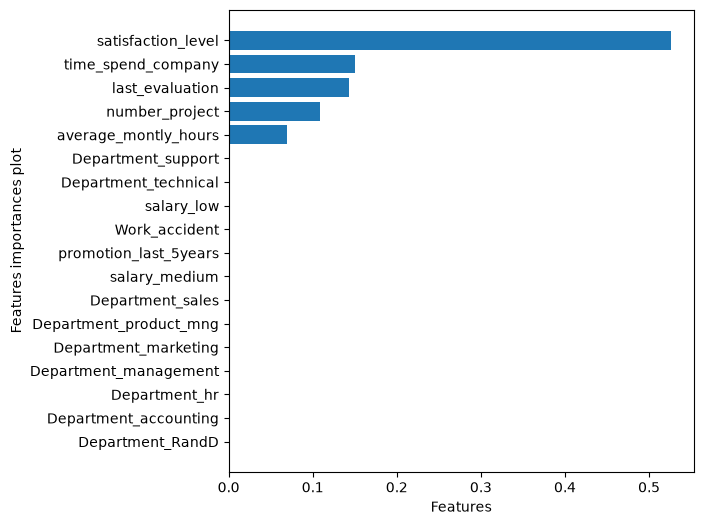

In [104]:
stud = pd.read_csv("HR_comma_sep.csv")
X , y = stud.drop('left', axis=1), stud['left'] 
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26 ,stratify=y)


bestTree = DecisionTreeClassifier(random_state=26,min_samples_split=2, min_samples_leaf=1,max_depth=7)
X_ohe = cols_trs.fit_transform(X)
bestTree.fit(X_ohe , y)

df_imp = pd.DataFrame({'features':list(X_ohe.columns),
                          'importance': bestTree.feature_importances_})
df_imp.sort_values('importance',inplace=True)
plt.figure(figsize=(6,6))
plt.barh(df_imp['features'], df_imp['importance'])
plt.xlabel('Features')
plt.ylabel('importance')
plt.title('Features importances plot')

# Decision Tree on heart
(find Best DT on hr dataset -> OHE -> DT -> features and features_importance_)

In [106]:

os.chdir('E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')
heart = pd.read_csv("heart.csv")
heart

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [ ]:
ohe = OneHotEncoder(sparse_output=False , drop='first').set_output(transform='pandas')
cols_trs = make_column_transformer(
    ( ohe, make_column_selector(dtype_include='object')),
    ( 'passthrough', make_column_selector(dtype_include=['int64', 'float64'])),
    verbose_feature_names_out=False
).set_output(transform = 'pandas')


In [112]:
X , y = heart.drop('target', axis=1), heart['target']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26 ,stratify=y)

 
depths = [None ,2,3,4,5,6,7]
min_split = [2,5,10,20,50]
min_leaf = [1,5,10,20,50]
scores = []

for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26 , max_depth=d , min_samples_split=s, min_samples_leaf=f)
 

            dtc.fit(X_train, y_train)
            y_pred = dtc.predict(X_test) 
              
            scores.append([d,s,f,accuracy_score(y_test, y_pred)])

df_scores  = pd.DataFrame(scores , columns=['Depth','Splits','Leaf','Score'])
df_scores.sort_values('Score' , ascending=False)

100%|██████████| 7/7 [00:00<00:00,  7.07it/s]


,Depth,Splits,Leaf,Score
111,5.0,10,5,0.813187
106,5.0,5,5,0.813187
101,5.0,2,5,0.813187
161,7.0,10,5,0.802198
1,NaN,2,5,0.802198
...,...,...,...,...
143,6.0,20,20,0.670330
158,7.0,5,20,0.670330
153,7.0,2,20,0.670330
163,7.0,10,20,0.670330


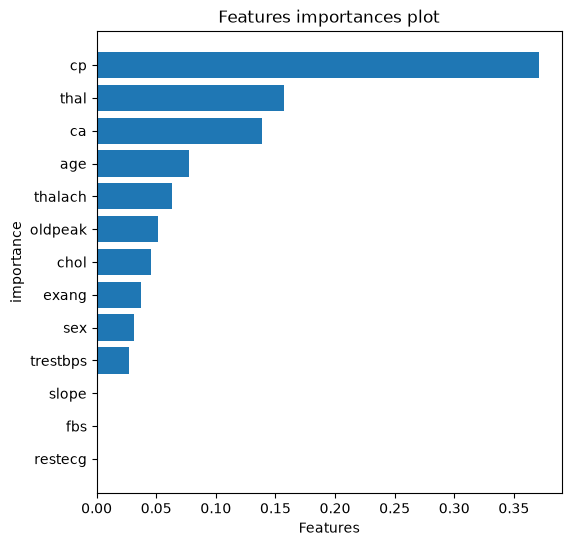

In [113]:
heart = pd.read_csv("heart.csv")
X , y = heart.drop('target', axis=1), heart['target']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26 ,stratify=y)


bestTree = DecisionTreeClassifier(random_state=26,min_samples_split=10, min_samples_leaf=5,max_depth=5)
X_ohe = cols_trs.fit_transform(X)
bestTree.fit(X_ohe , y)

df_imp = pd.DataFrame({'features':list(X_ohe.columns),
                          'importance': bestTree.feature_importances_})

df_imp.sort_values('importance',inplace=True)
plt.figure(figsize=(6,6))
plt.barh(df_imp['features'], df_imp['importance'])
plt.xlabel('Features')
plt.ylabel('importance')
plt.title('Features importances plot')

plt.show()